# 02 – Heterogeneity analysis
Relates measured heterogeneity to FedAvg accuracy across the native scenarios (EXP-01B) and the Dirichlet partitions (EXP-02).

In [1]:
import sys; sys.path.insert(0,'../src')
import json, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})

In [2]:
runs = pd.read_csv('../reports/tables/all_runs.csv'); print(runs.shape)

(479, 63)


In [3]:
pd.read_csv('../reports/tables/exp01b_scenarios.csv')

,axis_scenario,n,test_accuracy_mean,test_accuracy_sd,test_accuracy_ci_low,test_accuracy_ci_high,test_macro_f1_mean,test_macro_f1_sd,test_macro_f1_ci_low,test_macro_f1_ci_high,...,client_acc_min_sd,client_acc_min_ci_low,client_acc_min_ci_high,rounds_to_target_mean,rounds_to_target_sd,rounds_to_target_ci_low,rounds_to_target_ci_high,mean_pairwise_label_jsd,feature_mean_distance,sample_count_cv
0,combined_non_iid,5,0.65060,0.025565,0.618857,0.682343,0.643873,0.024406,0.613569,0.674177,...,0.056539,0.001524,0.141929,NaN,NaN,NaN,NaN,0.266272,7.207294,0.317350
1,feature_skew,5,0.74924,0.006834,0.740754,0.757726,0.749121,0.006905,0.740548,0.757694,...,0.024177,0.433897,0.493938,NaN,NaN,NaN,NaN,0.001011,7.087524,0.000000
2,iid,5,0.86892,0.000687,0.868067,0.869773,0.868890,0.000696,0.868026,0.869753,...,0.013442,0.775063,0.808443,4.2,0.836660,3.161149,5.238851,0.000930,0.328503,0.000000
3,label_skew,5,0.65932,0.021893,0.632137,0.686503,0.653007,0.019838,0.628374,0.677639,...,0.021378,0.381703,0.434791,NaN,NaN,NaN,NaN,0.273745,0.328503,0.000000
4,quantity_skew,5,0.86844,0.003148,0.864532,0.872348,0.868399,0.003153,0.864484,0.872314,...,0.041171,0.697669,0.799909,5.4,1.516575,3.516923,7.283077,0.001517,0.397316,0.351002


In [4]:
pd.read_csv('../reports/tables/exp02_alpha_algorithm.csv')

,alpha,algorithm,n,test_accuracy_mean,test_accuracy_sd,test_accuracy_ci_low,test_accuracy_ci_high,test_macro_f1_mean,test_macro_f1_sd,test_macro_f1_ci_low,...,rounds_to_target_ci_low,rounds_to_target_ci_high,auc_accuracy_curve_mean,auc_accuracy_curve_sd,auc_accuracy_curve_ci_low,auc_accuracy_curve_ci_high,volatility_last10_mean,volatility_last10_sd,volatility_last10_ci_low,volatility_last10_ci_high
0,10.0,fedavg,8,0.867150,0.008224,0.860275,0.874025,0.867111,0.008221,0.860238,...,3.500764,5.499236,0.852551,0.007802,0.846028,0.859073,0.001125,0.000353,0.000829,0.001420
1,10.0,fedprox,8,0.866225,0.008190,0.859378,0.873072,0.866185,0.008190,0.859338,...,6.081027,9.168973,0.836195,0.010001,0.827834,0.844556,0.001053,0.000332,0.000775,0.001331
2,1.0,fedavg,8,0.862725,0.009151,0.855074,0.870376,0.862420,0.009313,0.854634,...,3.427321,4.822679,0.850487,0.006262,0.845252,0.855722,0.003156,0.001472,0.001926,0.004386
3,1.0,fedprox,8,0.864075,0.008360,0.857086,0.871064,0.863860,0.008464,0.856784,...,6.588993,8.911007,0.831356,0.010873,0.822266,0.840446,0.002110,0.001078,0.001209,0.003011
4,0.5,fedavg,8,0.860250,0.008204,0.853391,0.867109,0.860064,0.008321,0.853107,...,3.286108,5.463892,0.844488,0.006696,0.838890,0.850086,0.006747,0.004316,0.003138,0.010355
5,0.5,fedprox,8,0.862775,0.007762,0.856286,0.869264,0.862672,0.007781,0.856167,...,6.933647,8.816353,0.826492,0.009129,0.818860,0.834124,0.004795,0.002636,0.002592,0.006999
6,0.1,fedavg,8,0.821225,0.052551,0.777291,0.865159,0.816679,0.059546,0.766897,...,4.476532,8.023468,0.794766,0.028515,0.770927,0.818606,0.047664,0.028120,0.024155,0.071173
7,0.1,fedprox,8,0.838200,0.035243,0.808736,0.867664,0.836187,0.038252,0.804208,...,8.179932,13.070068,0.785766,0.023286,0.766298,0.805234,0.026197,0.017888,0.011242,0.041152


Accuracy is nearly flat for α ≥ 0.5 but run-to-run variance (SD 0.053 at α = 0.1) and worst-client accuracy change dramatically – mean accuracy alone understates the effect of heterogeneity.

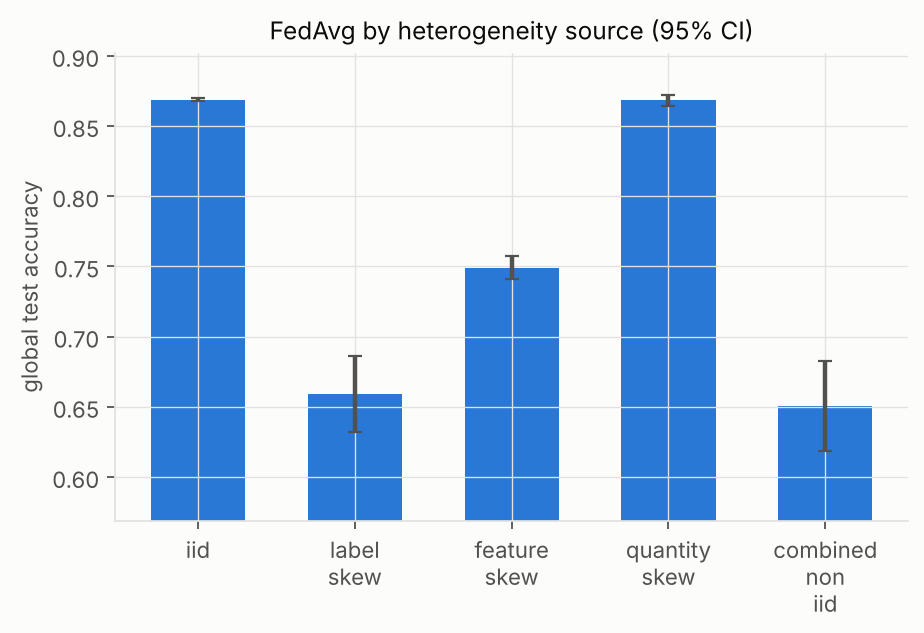

In [5]:
from IPython.display import Image, display
display(Image('../reports/figures/experiments/exp01b_heterogeneity_sources.png', width=640))

*Final test accuracy for each isolated heterogeneity source (mean ± 95% CI).*